# جلسهٔ ۳ — درخت چطور سؤالش را انتخاب می‌کند

*خلوص، غافلگیری، و بهره — قهرمانِ سؤال‌ها.*

In [1]:
# COURSE SETUP — identical in every session. Just run it. (5 seconds)
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from scipy.stats import entropy as _sc_entropy
import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    # Persian text for matplotlib: shapes + orders it correctly
    return get_display(arabic_reshaper.reshape(str(text)))

def surprise(labels):
    # the surprise level of a box (entropy) — from COUNTS, no formula needed.
    # base=2: measured in "bits" — the same numbers we used on the board.
    _, counts = np.unique(labels, return_counts=True)
    return float(_sc_entropy(counts, base=2))

plt.rcParams["figure.figsize"] = (8, 4)
print("Setup OK — let's measure some questions.")


Setup OK — let's measure some questions.


# PART 0 — نمایش: ماشین چطور سؤالش را انتخاب می‌کند

جلسهٔ قبل ماشین `وزن ≥ ۱۴` را پرسید و قول دادیم بگوییم **چرا**.
حالا بازیِ کلاس را جلوی چشم‌تان اجرا می‌کنیم: ماشین همهٔ سؤال‌های ممکن را
امتحان می‌کند، به هر کدام یک نمره می‌دهد — و قهرمان را انتخاب می‌کند.


In [ ]:
# دمو: ماشین سؤال‌ها را امتحان می‌کند و نمره می‌دهد
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "طول_گوش": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "گروه": ["گربه", "گربه", "گربه", "گربه",
             "سگ بزرگ", "سگ بزرگ", "سگ بزرگ", "سگ بزرگ",
             "سگ کوچک", "سگ کوچک", "سگ کوچک"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز",
          "بولداگ", "آلمانی", "گلدن", "دابلمان",
          "پودل", "یورکشایر", "پاپیلون"])
X = animals[["وزن", "طول_گوش"]]
y = animals["گروه"]


def surprise_after(feature, th):
    # نمرهٔ یک سؤال: میانگینِ غافلگیریِ دو طرفِ در، بعد از شکستن
    left  = y[animals[feature] <  th]
    right = y[animals[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return None
    return (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)

before = surprise(y)
print(f"غافلگیریِ جعبهٔ اصلی (۱۱ حیوان): {before:.2f}")
print()
print("جدول امتیازها — سؤال | غافلگیری بعد از سؤال | نمرهٔ سؤال (بهره):")
candidates = [("وزن", 14), ("طول_گوش", 8.25), ("وزن", 3.25), ("طول_گوش", 4.5), ("وزن", 30)]
for feature, th in candidates:
    after = surprise_after(feature, th)
    print(f"  {feature} ≥ {th:5}  |  {after:.2f}  |  بهره = {before - after:.2f}")

print()
best = max(candidates, key=lambda c: before - surprise_after(*c))
print(f"قهرمانِ ماشین: {best[0]} ≥ {best[1]}  (بیشترین بهره)")
print("همان سؤالی که جلسهٔ ۲ دیدیم — حالا می‌دانیم از کجا آمده.")


# PART A — جلسهٔ تدریس

*(این بخش را با معلم، در کلاس پر می‌کنیم.)*

## A1 — مرتب‌شدگی: کدام سؤال بهتر مرتب می‌کند؟

سؤالِ خوب، هر طرفِ در را «یک‌رنگ» می‌گذارد.
سؤالِ بیهوده، جعبه را تکه می‌کند ولی شلوغ‌ترش می‌کند.


In [3]:
# A1 — دو سؤال را کنار هم ببین: یکی مرتب می‌کند، یکی فقط تکه می‌کند
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "طول_گوش": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "گروه": ["گربه", "گربه", "گربه", "گربه",
             "سگ بزرگ", "سگ بزرگ", "سگ بزرگ", "سگ بزرگ",
             "سگ کوچک", "سگ کوچک", "سگ کوچک"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز",
          "بولداگ", "آلمانی", "گلدن", "دابلمان",
          "پودل", "یورکشایر", "پاپیلون"])
X = animals[["وزن", "طول_گوش"]]
y = animals["گروه"]

for feature, th, verdict in [("وزن", 14, "سؤالِ خوب"),
                             ("طول_گوش", 4.5, "سؤالِ بیهوده")]:
    left  = y[animals[feature] <  th].value_counts()
    right = y[animals[feature] >= th].value_counts()
    print(f"--- {feature} ≥ {th}  ({verdict}) ---")
    print("  درِ نه :", dict(left))
    print("  درِ بله:", dict(right))
    print()

# سؤال خوب: یک طرف فقط سگ بزرگ است (مرتب). سؤال بیهوده: هر دو طرف مثل قبلِ قاطی‌اند.


--- وزن ≥ 14  (سؤالِ خوب) ---
  درِ نه : {'گربه': np.int64(4), 'سگ کوچک': np.int64(3)}
  درِ بله: {'سگ بزرگ': np.int64(4)}

--- طول_گوش ≥ 4.5  (سؤالِ بیهوده) ---
  درِ نه : {'گربه': np.int64(1)}
  درِ بله: {'سگ بزرگ': np.int64(4), 'گربه': np.int64(3), 'سگ کوچک': np.int64(3)}



## A2 — غافلگیری: شلوغیِ جعبه را عددی کنیم

سه تا کیسهٔ توپ داریم. از هر کدام نمی‌بینیم یک توپ بیرون می‌کشیم:
- کیسهٔ ۱: ۸ توپ آبی
- کیسهٔ ۲: ۴ آبی + ۴ قرمز
- کیسهٔ ۳: ۳ آبی + ۳ قرمز + ۲ سبز

قبل از کشیدن، چقدر مطمئنید؟ همان «چقدر مطمئن نیستم»، **غافلگیری (آنتروپی)** است.


In [4]:
# A2 — خط‌کشِ ماشین: غافلگیریِ هر کیسه
bags = {
    "کیسهٔ ۱ (۸ آبی)":            ["آبی"] * 8,
    "کیسهٔ ۲ (۴ آبی + ۴ قرمز)":   ["آبی"] * 4 + ["قرمز"] * 4,
    "کیسهٔ ۳ (۳ آبی + ۳ قرمز + ۲ سبز)": ["آبی"] * 3 + ["قرمز"] * 3 + ["سبز"] * 2,
}
for name, bag in bags.items():
    print(f"{name:35} ← غافلگیری: {surprise(bag):.2f}")

# جعبهٔ خالص = ۰ غافلگیری. هرچه قاطی‌تر، عدد بزرگ‌تر. همین!


کیسهٔ ۱ (۸ آبی)                     ← غافلگیری: 0.00
کیسهٔ ۲ (۴ آبی + ۴ قرمز)            ← غافلگیری: 1.00
کیسهٔ ۳ (۳ آبی + ۳ قرمز + ۲ سبز)    ← غافلگیری: 1.56


In [5]:
# A2b — جعبهٔ ۱۱ حیوان چقدر غافلگیرکننده است؟ (اول حدس بزن، بعد اجرا کن)
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "طول_گوش": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "گروه": ["گربه", "گربه", "گربه", "گربه",
             "سگ بزرگ", "سگ بزرگ", "سگ بزرگ", "سگ بزرگ",
             "سگ کوچک", "سگ کوچک", "سگ کوچک"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز",
          "بولداگ", "آلمانی", "گلدن", "دابلمان",
          "پودل", "یورکشایر", "پاپیلون"])
X = animals[["وزن", "طول_گوش"]]
y = animals["گروه"]

print("ترکیب جعبه:", dict(y.value_counts()))
print(f"غافلگیریِ جعبهٔ حیوانات: {surprise(y):.2f}")


ترکیب جعبه: {'گربه': np.int64(4), 'سگ بزرگ': np.int64(4), 'سگ کوچک': np.int64(3)}
غافلگیریِ جعبهٔ حیوانات: 1.57


## A3 — بازیِ رتبه‌بندی سؤال‌ها

نمرهٔ هر سؤال = غافلگیریِ قبل − غافلگیریِ بعد.
سؤالی که بیشترین غافلگیری را بردارد، **قهرمان** است — ماشین همیشه قهرمان را انتخاب می‌کند.


In [6]:
# A3 — جدول امتیازها: ماشین همهٔ سؤال‌ها را می‌سنجد
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "طول_گوش": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "گروه": ["گربه", "گربه", "گربه", "گربه",
             "سگ بزرگ", "سگ بزرگ", "سگ بزرگ", "سگ بزرگ",
             "سگ کوچک", "سگ کوچک", "سگ کوچک"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز",
          "بولداگ", "آلمانی", "گلدن", "دابلمان",
          "پودل", "یورکشایر", "پاپیلون"])
X = animals[["وزن", "طول_گوش"]]
y = animals["گروه"]

def gain_of(feature, th):
    left  = y[animals[feature] <  th]
    right = y[animals[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)
    return surprise(y) - after

rows = []
for feature in ("وزن", "طول_گوش"):
    for th in (3.25, 4.5, 8.25, 14, 30):
        rows.append((f"{feature} ≥ {th}", gain_of(feature, th)))
board = pd.DataFrame(rows, columns=["سؤال", "بهره"]).sort_values("بهره", ascending=False)
board.index = range(1, len(board) + 1)
print(f"غافلگیریِ قبل از هر سؤال: {surprise(y):.2f}")
print(board.to_string())

# دو قهرمان مساوی‌اند (وزن ≥ ۱۴ و گوش ≥ ۸.۲۵) — ماشین اولین‌ که دیده را نگه می‌دارد: وزن.


غافلگیریِ قبل از هر سؤال: 1.57
              سؤال      بهره
1         وزن ≥ 14  0.945660
2       وزن ≥ 8.25  0.945660
3   طول_گوش ≥ 8.25  0.945660
4         وزن ≥ 30  0.320402
5        وزن ≥ 4.5  0.299896
6       وزن ≥ 3.25  0.144487
7    طول_گوش ≥ 4.5  0.144487
8   طول_گوش ≥ 3.25  0.000000
9     طول_گوش ≥ 14  0.000000
10    طول_گوش ≥ 30  0.000000


In [7]:
# A3b — حالا فقط جعبهٔ سبک (۷ حیوان: ۴ گربه + ۳ سگ کوچک). قهرمان کیست؟
light = animals[animals["وزن"] < 14]
y_light = light["گروه"]
def gain_light(feature, th):
    left  = y_light[light[feature] <  th]
    right = y_light[light[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_light)
    return surprise(y_light) - after

print("ترکیب جعبهٔ سبک:", dict(y_light.value_counts()))
print(f"غافلگیری: {surprise(y_light):.2f}")
for feature, th in [("طول_گوش", 8.25), ("طول_گوش", 7.0), ("وزن", 3.75)]:
    print(f"  {feature} ≥ {th:5} ← بهره: {gain_light(feature, th):.2f}")

# قهرمان: گوش ≥ ۸.۲۵ — جعبه را کاملاً خالص می‌کند (بهره = ۰.۹۹ = همهٔ غافلگیری).
# همین سؤالِ دومِ درختِ جلسهٔ ۲ است: خودتان پیدایش کردید.


ترکیب جعبهٔ سبک: {'گربه': np.int64(4), 'سگ کوچک': np.int64(3)}
غافلگیری: 0.99
  طول_گوش ≥  8.25 ← بهره: 0.99
  طول_گوش ≥   7.0 ← بهره: 0.52
  وزن ≥  3.75 ← بهره: 0.01


## A4 — لحظهٔ بزرگ: ماشین این بازی را روی تایتانیک بازی می‌کند

۷۱۲ مسافر (بعد از حذف سن‌های گم‌شده)، ۲۸۸ نفر زنده ماندند.
جعبهٔ تایتانیک چقدر غافلگیرکننده است؟


In [8]:
# A4 — جعبهٔ تایتانیک
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

print(f"مسافرها: {len(y_t)} — زنده‌مانده: {y_t.sum()} ({y_t.mean():.0%})")
print(f"غافلگیریِ جعبهٔ تایتانیک: {surprise(y_t):.2f}")


مسافرها: 712 — زنده‌مانده: 288 (40%)
غافلگیریِ جعبهٔ تایتانیک: 0.97


## A5 — جدول امتیازها روی تایتانیک: قهرمان کیست؟

جلسهٔ ۱ روی «کدام ویژگی مهم‌تر است» رأی گرفتید.
امروز رأی‌تان عدد دارد.


In [9]:
# A5 — بهرهٔ هر ویژگی روی تایتانیک (بهترین سؤالِ هر ویژگی)
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

def gain_feature(col):
    vals = sorted(X_t[col].unique())
    root = surprise(y_t)
    best = 0.0
    for i in range(len(vals) - 1):
        th = (vals[i] + vals[i + 1]) / 2
        left  = y_t[X_t[col] <= th]
        right = y_t[X_t[col] >  th]
        if len(left) == 0 or len(right) == 0:
            continue
        after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_t)
        best = max(best, root - after)
    return best

board = pd.DataFrame(
    [(c, gain_feature(c)) for c in X_t.columns],
    columns=["ویژگی", "بهره"]).sort_values("بهره", ascending=False)
board.index = range(1, len(board) + 1)
print(f"غافلگیریِ جعبه: {surprise(y_t):.2f}")
print(board.to_string())

# قهرمان: is_female — همان که جلسهٔ ۱ رأی‌تان بود. ماشین فقط عددش را گفت.
# (جعبهٔ مردها: ۲۱٪ زنده ماندند. جعبهٔ زن‌ها: ۷۵٪.)


غافلگیریِ جعبه: 0.97
       ویژگی      بهره
1  is_female  0.214108
2     pclass  0.083014
3       fare  0.069298
4        age  0.018469


## A6 — کلِ راز، در چند خط

ماشین فکر نمی‌کند؛ می‌سنجد و بزرگ‌ترین را برمی‌دارد — برای هر گره، میلیون‌ها بار.


In [10]:
# A6 — بازیِ ماشین، به‌صورت پایتونِ ساده (روی جعبهٔ حیوانات)
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "طول_گوش": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "گروه": ["گربه", "گربه", "گربه", "گربه",
             "سگ بزرگ", "سگ بزرگ", "سگ بزرگ", "سگ بزرگ",
             "سگ کوچک", "سگ کوچک", "سگ کوچک"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز",
          "بولداگ", "آلمانی", "گلدن", "دابلمان",
          "پودل", "یورکشایر", "پاپیلون"])
X = animals[["وزن", "طول_گوش"]]
y = animals["گروه"]

def best_question(table, labels):
    best_gain, best_q = 0.0, None
    for feature in ("وزن", "طول_گوش"):
        vals = sorted(table[feature].unique())
        for i in range(len(vals) - 1):
            th = (vals[i] + vals[i + 1]) / 2
            left  = labels[table[feature] <  th]
            right = labels[table[feature] >= th]
            if len(left) == 0 or len(right) == 0:
                continue
            after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(labels)
            g = surprise(labels) - after
            if g > best_gain:
                best_gain, best_q = g, (feature, th)
    return best_q, best_gain

q, g = best_question(animals, y)
print(f"قهرمان: {q[0]} ≥ {q[1]}  با بهرهٔ {g:.2f}")

# و برای گرهٔ دوم، همان بازی روی جعبهٔ سبک:
light = animals[animals["وزن"] < 14]
q2, g2 = best_question(light, light["گروه"])
print(f"قهرمانِ جعبهٔ سبک: {q2[0]} ≥ {q2[1]}  با بهرهٔ {g2:.2f}")

# این دو سؤال، دقیقاً درختِ عمق-۲ جلسهٔ ۲ هستند. خط چهارمی وجود ندارد.


قهرمان: وزن ≥ 14.0  با بهرهٔ 0.95
قهرمانِ جعبهٔ سبک: طول_گوش ≥ 8.25  با بهرهٔ 0.99


---

# PART B — تمرین‌های خانه (قبل از جلسهٔ حل مسئله)

## تمرین B1 — غافلگیریِ کیسه‌ها (۱ نمره)

سه کیسهٔ توپ داریم. غافلگیری (آنتروپی) هر کدام را با تابع `surprise` حساب کن
و جواب‌ها را در متغیرها بگذار (گرد نکن — همان عددی که چاپ می‌شود):

- کیسهٔ الف: ۱۰ توپ همه قرمز
- کیسهٔ ب: ۵ قرمز + ۵ آبی
- کیسهٔ ج: ۱ قرمز + ۹ آبی


In [11]:
# B1 — غافلگیریِ کیسه‌ها را حساب کن
bag_a = ["قرمز"] * 10
bag_b = ["قرمز"] * 5 + ["آبی"] * 5
bag_c = ["قرمز"] * 1 + ["آبی"] * 9

# TODO: با تابع surprise (سلول تنظیمات) هر سه را حساب کن و در متغیرها بگذار
B1_surprise_a = None   # <-- پاسخ تو
B1_surprise_b = None   # <-- پاسخ تو
B1_surprise_c = None   # <-- پاسخ تو
print(f"الف: {B1_surprise_a}، ب: {B1_surprise_b}، ج: {B1_surprise_c}")


الف: None، ب: None، ج: None


## تمرین B2 — سؤالِ قهرمانِ جعبهٔ سبک (۱ نمره)

جعبهٔ سبک (۷ حیوان: ۴ گربه + ۳ سگ کوچک) را داری.
بین این سه سؤال، قهرمان کدام است؟ با تابع بهره حساب کن:

- `طول_گوش ≥ 8.25`
- `طول_گوش ≥ 7.0`
- `وزن ≥ 3.75`


In [12]:
# B2 — بهرهٔ هر سه سؤال را حساب کن، قهرمان را انتخاب کن
light = animals[animals["وزن"] < 14]
y_light = light["گروه"]

def gain_light(feature, th):
    left  = y_light[light[feature] <  th]
    right = y_light[light[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_light)
    return surprise(y_light) - after

# TODO: بهرهٔ سه سؤال را حساب کن؛ سؤالِ قهرمان را (رشتهٔ کامل، مثل "طول_گوش ≥ 8.25") در B2_champion بگذار
B2_gain_ears_825 = None   # <-- بهرهٔ سؤال اول
B2_gain_ears_70  = None   # <-- بهرهٔ سؤال دوم
B2_gain_weight_375 = None # <-- بهرهٔ سؤال سوم
B2_champion = ""          # <-- نام سؤالِ قهرمان (رشته)
print(f"قهرمان: {B2_champion}")


قهرمان: 


## تمرین B3 — سؤالِ قهرمانِ تایتانیک (۱ نمره — تحویلِ امشب)

جدول امتیازهای تایتانیک را مثل سلول A5 بساز. قهرمان کدام ویژگی است؟
بهرهٔ او را هم بنویس. بعد جعبهٔ قهرمان را بکش: دو جعبه (بله/خیر) با تعداد زنده‌مانده‌ها —
عنوان‌ها و اعداد را خودت بنویس. **همین تصویر، کشتیِ امشبِ توست.**


قهرمان:  با بهرهٔ 0.000


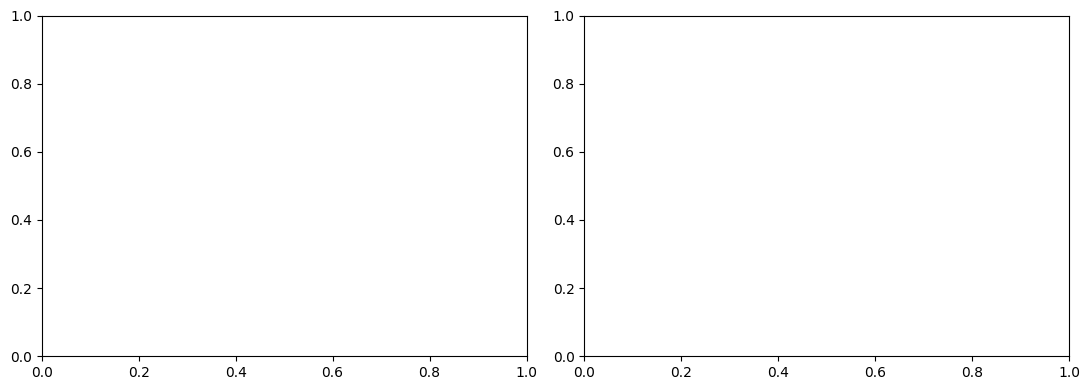

In [13]:
# B3 — قهرمانِ تایتانیک + جعبه‌های قبل/بعد (تحویل امشب)
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

# TODO: مثل A5 بهرهٔ بهترین سؤالِ هر ویژگی را حساب کن
# TODO: نام ویژگیِ قهرمان را در B3_champion_feature بگذار (یکی از: "is_female", "pclass", "fare", "age")
# TODO: بهرهٔ قهرمان را در B3_champion_gain بگذار (عدد)
B3_champion_feature = ""
B3_champion_gain = 0.0
print(f"قهرمان: {B3_champion_feature} با بهرهٔ {B3_champion_gain:.3f}")

# حالا جعبهٔ قبل/بعد را بکش (مثل نمودارهای جلسهٔ ۱ — خودت کاملش کن)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# TODO (بخش تصویری): در axes[0] جعبهٔ کامل: نوارِ «زنده/نزنده» با تعداد ۲۸۸ و ۴۲۴
# TODO (بخش تصویری): در axes[1] دو جعبهٔ بعد از سؤالِ قهرمان: مردها و زن‌ها با تعداد زنده‌مانده‌ها
plt.tight_layout(); plt.show()


---

# PART C — جلسهٔ حل مسئله
*(اول تمرین‌های خانه را زنده حل می‌کنیم — بعد این‌ها را)*

## C1 — بازیِ آستانهٔ ثابت

ماشین می‌گوید `وزن ≥ 14`. ولی `وزن ≥ 20` هم همین‌قدر خوب است؟
برای هر عدد بین ۱ تا ۳۰، بهرهٔ سؤالِ `وزن ≥ عدد` را حساب کن و نمودارش را ببین.


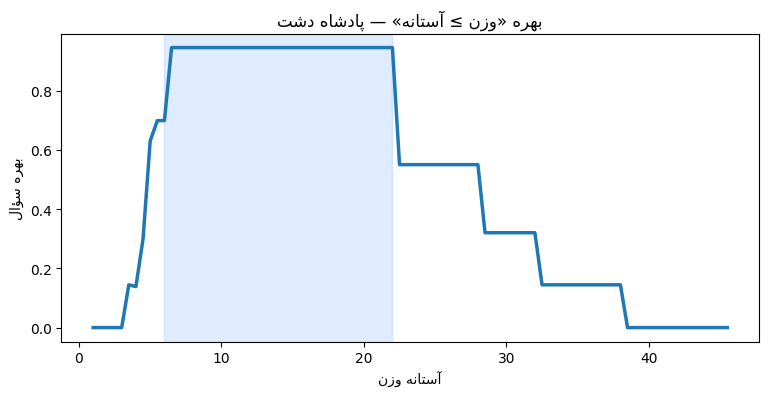

In [14]:
# C1 — نمودار بهره بر حسب آستانه
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "طول_گوش": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "گروه": ["گربه", "گربه", "گربه", "گربه",
             "سگ بزرگ", "سگ بزرگ", "سگ بزرگ", "سگ بزرگ",
             "سگ کوچک", "سگ کوچک", "سگ کوچک"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز",
          "بولداگ", "آلمانی", "گلدن", "دابلمان",
          "پودل", "یورکشایر", "پاپیلون"])
X = animals[["وزن", "طول_گوش"]]
y = animals["گروه"]

def gain_of(feature, th):
    left  = y[animals[feature] <  th]
    right = y[animals[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)
    return surprise(y) - after

ths = np.arange(1, 46, 0.5)
gains = [gain_of("وزن", t) for t in ths]
plt.figure(figsize=(9, 4))
plt.plot(ths, gains, lw=2.5)
plt.axvspan(6, 22, color="#2D7FF9", alpha=0.15)
plt.xlabel(fa("آستانهٔ وزن")); plt.ylabel(fa("بهرهٔ سؤال"))
plt.title(fa("بهرهٔ «وزن ≥ آستانه» — پادشاهِ دشت"))
plt.show()

# بحث: چرا هر عددی بین ۶ و ۲۲ (ناحیهٔ آبی) قهرمان است؟
# (چون همهٔ گربه‌ها و سگ‌های کوچک سبک‌تر و همهٔ سگ‌های بزرگ سنگین‌ترند —
#  هر آستانه‌ای بین این دو دسته، یک‌جا را قفل می‌کند.)


## C2 — قهرمانِ یک‌حیوانی

جعبهٔ جدید: ۱۰ سگ بزرگ + ۱ گربه.
سؤالِ `وزن ≥ 20` فقط ۱ حیوان را جدا می‌کند. بهره‌اش چقدر است؟
سؤال‌های دیگر هم امتحان کن — سؤالی که «بیشترین حیوان را جدا می‌کند» برنده است یا نه؟


In [15]:
# C2 — جعبهٔ ۱۰+۱: سؤالِ کوچک، بهرهٔ بزرگ
box = pd.DataFrame({
    "وزن": [3.0] + [22, 25, 28, 30, 32, 35, 38, 40, 45, 50],
    "گروه": ["گربه"] + ["سگ بزرگ"] * 10})
y_box = box["گروه"]
def gain_box(th):
    left  = y_box[box["وزن"] <  th]
    right = y_box[box["وزن"] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_box)
    return surprise(y_box) - after

print(f"غافلگیریِ جعبه: {surprise(y_box):.3f}")
for th in (20, 34, 44, 55):
    print(f"  وزن ≥ {th:3} ← بهره: {gain_box(th):.3f}")

# بحث: «وزن ≥ 20» فقط یک حیوان جدا می‌کند ولی جعبه را کاملاً خالص می‌کند —
# بهره‌اش از «وزن ≥ 34» (که ۵ حیوان جدا می‌کند ولی دو طرف را قاطی نگه می‌دارد) بیشتر است.
# قهرمان یعنی بیشترین «مرتب‌شدگی»، نه بیشترین «جداکردن».


غافلگیریِ جعبه: 0.439
  وزن ≥  20 ← بهره: 0.439
  وزن ≥  34 ← بهره: 0.085
  وزن ≥  44 ← بهره: 0.028
  وزن ≥  55 ← بهره: 0.000


## C3 — راند دومِ تایتانیک: قهرمانِ جعبهٔ زن‌ها

سؤالِ اولِ تایتانیک `is_female` بود. حالا داخلِ جعبهٔ زن‌ها (۲۵۹ نفر، ۷۵٪ زنده)
دوباره بازی کنیم: قهرمانِ راند دوم کیست؟ (کلاس؟ سن؟ کرایه؟)

**بحث پایانی:** سؤال‌ها فقط از میانِ ستون‌های جدول انتخاب می‌شوند.
اگر ستونی دربارهٔ «کدام قایق» وجود داشت چه می‌شد؟ این یعنی انتخابِ ویژگی‌ها
کارِ ماست — ماشین فقط بینِ چیزی که داده‌ایم می‌گردد.


In [16]:
# C3 — راند دوم: جعبهٔ زن‌ها
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

women = X_t[X_t["is_female"] == 1]
y_w = y_t[X_t["is_female"] == 1]
print(f"جعبهٔ زن‌ها: {len(y_w)} نفر، {y_w.mean():.0%} زنده، غافلگیری {surprise(y_w):.2f}")

def gain_w(col):
    vals = sorted(women[col].unique())
    root = surprise(y_w)
    best = 0.0
    for i in range(len(vals) - 1):
        th = (vals[i] + vals[i + 1]) / 2
        left  = y_w[women[col] <= th]
        right = y_w[women[col] >  th]
        if len(left) == 0 or len(right) == 0:
            continue
        after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_w)
        best = max(best, root - after)
    return best

for c in ("pclass", "age", "fare"):
    print(f"  بهترین سؤالِ {c:10} ← بهره: {gain_w(c):.3f}")

# بحث: راند دومِ درختِ واقعی تایتانیک، همان چیزی است که در عکسِ درختِ جلسهٔ ۱ دیدید.


جعبهٔ زن‌ها: 259 نفر، 75% زنده، غافلگیری 0.81
  بهترین سؤالِ pclass     ← بهره: 0.223
  بهترین سؤالِ age        ← بهره: 0.013
  بهترین سؤالِ fare       ← بهره: 0.100
